# Week 5 — Position-0 sink control (V & K) and parallel-corpus control (FLORES-200)

Weeks 2–4 showed that low-rank compression of **late-layer values (`V`, layers 21–27)** with an English basis heavily penalizes Quechua (`+0.265` nats/token in `head`, `+0.092` in `joint`), that leave-one-out multilingual calibration (`multi_loo`) does not rescue Quechua, and that mixing just **5k tokens of Quechua** (`w = 0.05–0.10`) into a `joint` projector closes the gap almost completely.

This notebook runs two high-priority methodological controls before scaling to a second model family:

1. **Part A — Position-0 (attention sink) control on Wikipedia (`V` and `K`):**
   Weeks 1–4 computed Gram matrices with `SKIP_FIRST_TOKENS = 1` (excluding position 0 so attention sinks do not dominate the spectrum), but `project_hook` projected *all* token positions including position 0. Here we compare `protect_pos0 = False` (Week 2–4 behavior) vs `protect_pos0 = True` (leave position 0 untouched, matching `SKIP_FIRST_TOKENS = 1`) on:
   - Late-layer `V` (`r = 0.25`, `head` & `joint`): verifies that the Quechua calibration penalty is not a position-0 artifact.
   - Late-layer `K` (`r = 0.25` `head`/`joint`, and `r = 0.75` `head`): tests whether projecting an unprotected position-0 sink explains why `K` blew up (`+57–120%` PPL even at `r = 0.75` oracle, and why `joint r = 0.25` beat `head r = 0.75`).
   - All-layer `V` (`r = 0.25`, `joint`): quick check on whether position-0 distortion drove all-layer collapse.
2. **Part B — Parallel-corpus control on FLORES-200 (`V`, late layers, `r = 0.25`):**
   Wikipedia is not parallel (`qu` needed 964 short articles vs 477–551 for `en/es/fi`). We replicate the core `V` result on **FLORES-200** (`eng_Latn`, `spa_Latn`, `fin_Latn`, `quy_Latn`) — exact translated sentences across all four languages — under two calibration regimes:
   - `wiki_to_flores`: Wikipedia bases (including the `5k` low-resource mixture) evaluated on parallel FLORES `devtest` (tests both parallel eval and cross-domain transfer).
   - `flores_to_flores`: FLORES `dev` bases (equal token budget across languages, strictly parallel text) evaluated on FLORES `devtest` (purest test of language vs topic).

**Kaggle settings.** GPU T4 ×1, Internet On. Run once with `SMOKE_TEST = True` on CPU first.
Expected runtime on one T4: ~45 min full (`QUICK = True` cuts it to ~18 min).

In [1]:
import os

SMOKE_TEST = os.environ.get("SMOKE_TEST", "0") == "1"   # True for <30s CPU dry run
QUICK = False                                           # True: smaller grid (~18 min on T4)

MODEL_ID = "Qwen/Qwen3-1.7B"
LANGS = ["en", "es", "fi", "qu"]
FLORES_CODES = {
    "en": "eng_Latn",
    "es": "spa_Latn",
    "fi": "fin_Latn",
    "qu": "quy_Latn",
}
WIKI_SNAPSHOT = "20231101"

SEQ_LEN = 512
CALIB_TOKENS = 150_000          # Wikipedia calibration budget per language
EVAL_TOKENS = 60_000            # Wikipedia evaluation budget per language
LOW_BUDGET_WINDOWS = 10         # 10 * 512 = 5,120 tokens (~5k low-resource recipe from Week 4)
MIX_WEIGHT = 0.10               # target-language weight for the 5k mixture
MAX_TOKENS_PER_ARTICLE = 2048
MIN_CHARS_PER_ARTICLE = 500
MIN_FILL = 0.5

CALIB_BATCH = 8
EVAL_BATCH = 4
SKIP_FIRST_TOKENS = 1
LATE_FROM = 0.75                # layers 21-27 for Qwen3-1.7B
R_V = 0.25
SCOPES = ("head", "joint")
N_BOOT = 2000
SEED = 0

OUT_DIR = "/kaggle/working/kv_rank_week5" if os.path.isdir("/kaggle/working") else "./kv_rank_week5"
os.makedirs(OUT_DIR, exist_ok=True)

if SMOKE_TEST:
    LANGS = ["aa", "bb", "cc"]
    FLORES_CODES = {"aa": "aa", "bb": "bb", "cc": "cc"}
    SEQ_LEN = 64
    CALIB_TOKENS = 64 * 24
    EVAL_TOKENS = 64 * 12
    LOW_BUDGET_WINDOWS = 4
    CALIB_BATCH, EVAL_BATCH, N_BOOT = 8, 4, 200

print(f"SMOKE_TEST={SMOKE_TEST} | QUICK={QUICK} | output -> {OUT_DIR}")

SMOKE_TEST=False | QUICK=False | output -> /kaggle/working/kv_rank_week5


In [2]:
import itertools, json, math, tarfile, time, urllib.request, zlib
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(SEED)
np.random.seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device, "| torch:", torch.__version__)

device: cuda | torch: 2.11.0+cu130


## 1. Model

In [3]:
from transformers import AutoModelForCausalLM, AutoTokenizer

if SMOKE_TEST:
    from transformers import LlamaConfig, LlamaForCausalLM
    model = LlamaForCausalLM(LlamaConfig(
        vocab_size=1000, hidden_size=64, intermediate_size=128,
        num_hidden_layers=4, num_attention_heads=4,
        num_key_value_heads=2, max_position_embeddings=256,
    ))
    tokenizer = None
else:
    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
    half = torch.float16 if device == "cuda" else torch.float32
    try:
        model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=half)
    except TypeError:
        model = AutoModelForCausalLM.from_pretrained(MODEL_ID, torch_dtype=half)

model.to(device).eval()

cfg = model.config
N_LAYERS = cfg.num_hidden_layers
N_KV = getattr(cfg, "num_key_value_heads", None) or cfg.num_attention_heads
HEAD_DIM = getattr(cfg, "head_dim", None) or cfg.hidden_size // cfg.num_attention_heads
D_KV = N_KV * HEAD_DIM
LATE = list(range(int(round(LATE_FROM * N_LAYERS)), N_LAYERS))
ALL_LAYERS = list(range(N_LAYERS))

PROJ = {"K": [], "V": []}
for name, mod in model.named_modules():
    if name.endswith("self_attn.k_proj"):
        PROJ["K"].append(mod)
    if name.endswith("self_attn.v_proj"):
        PROJ["V"].append(mod)
assert len(PROJ["K"]) == len(PROJ["V"]) == N_LAYERS
print(f"layers={N_LAYERS} kv_heads={N_KV} head_dim={HEAD_DIM} late={LATE[0]}–{LATE[-1]}")

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

layers=28 kv_heads=8 head_dim=128 late=21–27


## 2. Data: Wikipedia splits + FLORES-200 parallel corpus

- **Wikipedia** uses the exact same CRC32 article-id split and seed as Weeks 2–4 so Part A is directly comparable.
- **FLORES-200** loads line-aligned parallel sentences (`dev`: 997 sentences, `devtest`: 1,012 sentences) via an ungated multi-source loader (official Meta tarball first, then Hugging Face Parquet mirrors).
  - Sentences are packed with `\n` separators into full `SEQ_LEN` windows so every language covers the **exact same semantic text** while preserving identical sequence length and RoPE positions.
  - For `flores_dev` calibration, we also record a token-matched subset (`min_dev_windows` across all languages) so calibration budgets are strictly equal on parallel text.

In [4]:
def wiki_splits(lang):
    from datasets import load_dataset
    ds = load_dataset("wikimedia/wikipedia", f"{WIKI_SNAPSHOT}.{lang}", split="train", streaming=True)
    ds = ds.shuffle(seed=SEED, buffer_size=2000)
    need = {"calib": CALIB_TOKENS // SEQ_LEN, "eval": EVAL_TOKENS // SEQ_LEN}
    win = {"calib": [], "eval": []}
    for row in ds:
        if len(row["text"]) < MIN_CHARS_PER_ARTICLE:
            continue
        split = "calib" if zlib.crc32(str(row["id"]).encode()) % 2 == 0 else "eval"
        if len(win[split]) >= need[split]:
            if all(len(win[s]) >= need[s] for s in win):
                break
            continue
        ids = tokenizer(row["text"], add_special_tokens=False)["input_ids"][:MAX_TOKENS_PER_ARTICLE]
        for i in range(0, len(ids) - SEQ_LEN + 1, SEQ_LEN):
            if len(win[split]) < need[split]:
                win[split].append(ids[i:i + SEQ_LEN])
    for s in win:
        got = len(win[s])
        if got < MIN_FILL * need[s]:
            raise RuntimeError(f"{lang}/{s}: only {got}/{need[s]} windows; lower token budget")
    return {s: torch.tensor(w, dtype=torch.long) for s, w in win.items()}


FLORES_CACHE = os.path.join(OUT_DIR, "_flores200")


def _download_flores_tarball():
    dev_dir = os.path.join(FLORES_CACHE, "flores200_dataset", "dev")
    if os.path.isdir(dev_dir):
        return os.path.join(FLORES_CACHE, "flores200_dataset")
    os.makedirs(FLORES_CACHE, exist_ok=True)
    tgz = os.path.join(FLORES_CACHE, "flores200_dataset.tar.gz")
    for url in (
        "https://dl.fbaipublicfiles.com/nllb/flores200_dataset.tar.gz",
        "https://tinyurl.com/flores200dataset",
    ):
        try:
            print(f"Downloading FLORES-200 from {url} ...")
            urllib.request.urlretrieve(url, tgz)
            with tarfile.open(tgz, "r:gz") as tf:
                tf.extractall(FLORES_CACHE)
            if os.path.isdir(dev_dir):
                return os.path.join(FLORES_CACHE, "flores200_dataset")
        except Exception as e:
            print(f"  tarball attempt failed ({url}): {e}")
    return None


def _extract_text_column(ds):
    for col in ("sentence", "text", "target", "source"):
        if col in ds.column_names:
            return [str(x).strip() for x in ds[col]]
    raise KeyError(f"Could not find text column in {ds.column_names}")


def load_flores_sentences(code, split):
    """Load parallel FLORES-200 sentences for `code` and `split` ('dev' or 'devtest')."""
    root = _download_flores_tarball()
    if root is not None:
        p = os.path.join(root, split, f"{code}.{split}")
        if os.path.isfile(p):
            with open(p, encoding="utf-8") as fh:
                return [line.strip() for line in fh if line.strip()]

    from datasets import load_dataset
    # Fallback 1: community ungated Parquet mirror
    try:
        sp = "validation" if split == "dev" else "test"
        ds = load_dataset("tomasmajercik/flores-parquet", name=code, split=sp)
        return _extract_text_column(ds)
    except Exception as e:
        print(f"  tomasmajercik/flores-parquet fallback failed ({code}/{split}): {e}")

    # Fallback 2: official FLORES+ (works if HF_TOKEN is set)
    try:
        ds = load_dataset("openlanguagedata/flores_plus", code, split=split)
        return _extract_text_column(ds)
    except Exception as e:
        print(f"  openlanguagedata/flores_plus fallback failed ({code}/{split}): {e}")

    # Fallback 3: legacy facebook/flores
    ds = load_dataset("facebook/flores", code, split=split, trust_remote_code=True)
    return _extract_text_column(ds)


def pack_sentences(sentences):
    """Concatenate parallel sentences with newline separators into full SEQ_LEN windows."""
    sep = tokenizer("\n", add_special_tokens=False)["input_ids"]
    buf, n_toks = [], 0
    for s in sentences:
        ids = tokenizer(s, add_special_tokens=False)["input_ids"]
        n_toks += len(ids)
        buf.extend(ids)
        buf.extend(sep)
    n_win = len(buf) // SEQ_LEN
    arr = torch.tensor(buf[:n_win * SEQ_LEN], dtype=torch.long).view(n_win, SEQ_LEN)
    return arr, n_toks / max(1, len(sentences))


def smoke_all_splits(lang):
    lo = {"aa": 0, "bb": 300, "cc": 600}[lang]
    g = torch.Generator().manual_seed(SEED + lo)
    mk = lambda n: torch.randint(lo, lo + 300, (n // SEQ_LEN, SEQ_LEN), generator=g)
    wiki = {"calib": mk(CALIB_TOKENS), "eval": mk(EVAL_TOKENS)}
    flores = {"dev": mk(CALIB_TOKENS // 2), "devtest": mk(EVAL_TOKENS)}
    return wiki, flores, 25.0


wiki_data, flores_data, fertility = {}, {}, {}
for lang in LANGS:
    t0 = time.time()
    if SMOKE_TEST:
        wiki_data[lang], flores_data[lang], fertility[lang] = smoke_all_splits(lang)
    else:
        wiki_data[lang] = wiki_splits(lang)
        dev_sents = load_flores_sentences(FLORES_CODES[lang], "dev")
        test_sents = load_flores_sentences(FLORES_CODES[lang], "devtest")
        assert len(dev_sents) > 500 and len(test_sents) > 500, (lang, len(dev_sents), len(test_sents))
        dev_win, fert_dev = pack_sentences(dev_sents)
        test_win, fert_test = pack_sentences(test_sents)
        flores_data[lang] = {"dev": dev_win, "devtest": test_win}
        fertility[lang] = round((fert_dev + fert_test) / 2, 2)
    print(
        f"{lang}: wiki calib {tuple(wiki_data[lang]['calib'].shape)} eval {tuple(wiki_data[lang]['eval'].shape)} | "
        f"flores dev {tuple(flores_data[lang]['dev'].shape)} devtest {tuple(flores_data[lang]['devtest'].shape)} "
        f"(~{fertility[lang]} tok/sent, {time.time()-t0:.0f}s)"
    )

# Equalize FLORES dev calibration windows across languages so token budgets match strictly
min_fdev = min(len(flores_data[l]["dev"]) for l in LANGS)
for lang in LANGS:
    flores_data[lang]["dev_eq"] = flores_data[lang]["dev"][:min_fdev]
print(f"\nFLORES dev equalized calibration budget: {min_fdev} windows ({min_fdev * SEQ_LEN:,} tokens/lang)")

README.md:   0%|          | 0.00/131k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/41 [00:00<?, ?it/s]

/tmp/ipykernel_23/3617524879.py:43: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tf.extractall(FLORES_CACHE)


en: wiki calib (292, 512) eval (117, 512) | flores dev (53, 512) devtest (55, 512) (~26.81 tok/sent, 10s)
es: wiki calib (292, 512) eval (117, 512) | flores dev (80, 512) devtest (84, 512) (~40.81 tok/sent, 8s)
fi: wiki calib (292, 512) eval (117, 512) | flores dev (103, 512) devtest (108, 512) (~52.92 tok/sent, 7s)
qu: wiki calib (292, 512) eval (117, 512) | flores dev (107, 512) devtest (113, 512) (~55.21 tok/sent, 6s)

FLORES dev equalized calibration budget: 53 windows (27,136 tokens/lang)


## 3. Gram matrices, low-budget snapshots (`5k`), and baseline perplexities

We collect:
1. Full Wikipedia calibration Grams (`150k` tokens) + low-budget `5k` snapshots (`10` windows) for every language.
2. Wikipedia held-out evaluation Grams + baseline per-window NLLs.
3. FLORES `dev_eq` parallel calibration Grams + `5k` snapshots.
4. FLORES `devtest` parallel evaluation Grams + baseline per-window NLLs.
5. **Position-0 diagnostic:** per-layer norms of position 0 vs positions `1..T-1`, and how much of position 0's energy is captured by the `SKIP_FIRST_TOKENS = 1` projectors.

In [5]:
class GramCollector:
    def __init__(self, skip_first=SKIP_FIRST_TOKENS):
        self.skip = skip_first
        self.gram = {k: torch.zeros(N_LAYERS, D_KV, D_KV, dtype=torch.float64, device=device) for k in ("K", "V")}
        self.n_tok = 0
        self.handles = [m.register_forward_hook(self._hook(k, l)) for k in ("K", "V") for l, m in enumerate(PROJ[k])]

    def _hook(self, kind, layer):
        def fn(mod, inp, out):
            x = out[:, self.skip:, :].reshape(-1, out.shape[-1]).float()
            self.gram[kind][layer] += (x.T @ x).double()
            if kind == "K" and layer == 0:
                self.n_tok += x.shape[0]
        return fn

    def snapshot(self):
        return {k: (g / self.n_tok).cpu().numpy() for k, g in self.gram.items()}

    def result(self):
        for h in self.handles:
            h.remove()
        return self.snapshot()


@torch.no_grad()
def forward_collect(windows, batch, snap_at=None):
    c = GramCollector(skip_first=SKIP_FIRST_TOKENS)
    snaps = {}
    if snap_at is not None and snap_at < len(windows):
        # Run prefix [0:snap_at] at full batch size, take exact snapshot, then continue
        for i in range(0, snap_at, batch):
            model(input_ids=windows[i:min(i + batch, snap_at)].to(device), use_cache=False)
        snaps[snap_at] = c.snapshot()
        for i in range(snap_at, len(windows), batch):
            model(input_ids=windows[i:i + batch].to(device), use_cache=False)
    else:
        for i in range(0, len(windows), batch):
            model(input_ids=windows[i:i + batch].to(device), use_cache=False)
        if snap_at is not None:
            snaps[snap_at] = c.snapshot()
    return c.result(), snaps


@torch.no_grad()
def window_nll(windows, batch):
    out = []
    for i in range(0, len(windows), batch):
        ids = windows[i:i + batch].to(device)
        logits = model(input_ids=ids, use_cache=False).logits[:, :-1].float()
        nll = F.cross_entropy(logits.reshape(-1, logits.shape[-1]), ids[:, 1:].reshape(-1), reduction="none")
        out.append(nll.view(ids.shape[0], -1).mean(1).cpu())
        del logits, nll
    return torch.cat(out).numpy().astype(np.float64)


gram_wiki_calib, gram_wiki_5k, gram_wiki_eval, base_wiki_nll = {}, {}, {}, {}
gram_fl_calib, gram_fl_5k, gram_fl_eval, base_fl_nll = {}, {}, {}, {}

for lang in LANGS:
    t0 = time.time()
    g_wc, snaps_w = forward_collect(wiki_data[lang]["calib"], CALIB_BATCH, snap_at=LOW_BUDGET_WINDOWS)
    gram_wiki_calib[lang] = g_wc
    gram_wiki_5k[lang] = snaps_w[LOW_BUDGET_WINDOWS]

    c = GramCollector(skip_first=SKIP_FIRST_TOKENS)
    base_wiki_nll[lang] = window_nll(wiki_data[lang]["eval"], EVAL_BATCH)
    gram_wiki_eval[lang] = c.result()

    g_fc, snaps_f = forward_collect(flores_data[lang]["dev_eq"], CALIB_BATCH, snap_at=LOW_BUDGET_WINDOWS)
    gram_fl_calib[lang] = g_fc
    gram_fl_5k[lang] = snaps_f[LOW_BUDGET_WINDOWS]

    c = GramCollector(skip_first=SKIP_FIRST_TOKENS)
    base_fl_nll[lang] = window_nll(flores_data[lang]["devtest"], EVAL_BATCH)
    gram_fl_eval[lang] = c.result()

    if device == "cuda":
        torch.cuda.empty_cache()
    print(
        f"{lang}: wiki ppl={math.exp(base_wiki_nll[lang].mean()):.2f} | "
        f"flores ppl={math.exp(base_fl_nll[lang].mean()):.2f} ({time.time()-t0:.0f}s)"
    )

with open(os.path.join(OUT_DIR, "baseline_ppl.json"), "w") as fh:
    json.dump({
        "wiki": {l: math.exp(v.mean()) for l, v in base_wiki_nll.items()},
        "flores": {l: math.exp(v.mean()) for l, v in base_fl_nll.items()},
        "flores_tok_per_sent": fertility,
    }, fh, indent=2)

en: wiki ppl=16.39 | flores ppl=22.93 (97s)
es: wiki ppl=12.53 | flores ppl=14.89 (111s)
fi: wiki ppl=15.89 | flores ppl=21.48 (116s)
qu: wiki ppl=35.53 | flores ppl=168.61 (117s)


In [6]:
def top_basis(G, r):
    lam, U = np.linalg.eigh(G)
    return U[:, ::-1][:, :r]


def blocks(G):
    return [G[h * HEAD_DIM:(h + 1) * HEAD_DIM, h * HEAD_DIM:(h + 1) * HEAD_DIM] for h in range(N_KV)]


def captured(U, G):
    return float(np.einsum("ij,ik,kj->", U, G, U))


def make_projector(G_layer, scope, f):
    if scope == "head":
        r = max(1, round(f * HEAD_DIM))
        P = np.stack([(lambda U: U @ U.T)(top_basis(B, r)) for B in blocks(G_layer)])   # (N_KV, hd, hd)
    else:
        r = max(1, round(f * D_KV))
        U = top_basis(G_layer, r)
        P = U @ U.T                                                                     # (D, D)
    return torch.tensor(P, dtype=next(model.parameters()).dtype, device=device)


def project_hook(P, scope, protect_pos0=False):
    skip = SKIP_FIRST_TOKENS if protect_pos0 else 0
    def fn(mod, inp, out):
        tail = out[:, skip:, :] if skip > 0 else out
        if scope == "head":
            B, T, _ = tail.shape
            proj = torch.einsum("btnd,nde->btne", tail.reshape(B, T, N_KV, HEAD_DIM), P).reshape(B, T, D_KV)
        else:
            proj = tail @ P
        if skip > 0:
            return torch.cat([out[:, :skip, :], proj], dim=1)
        return proj
    return fn


def run_config(eval_windows, gram_src, kind, scope, f, layers, protect_pos0=False):
    handles = [
        PROJ[kind][l].register_forward_hook(
            project_hook(make_projector(gram_src[kind][l], scope, f), scope, protect_pos0=protect_pos0)
        )
        for l in layers
    ]
    try:
        return window_nll(eval_windows, EVAL_BATCH)
    finally:
        for h in handles:
            h.remove()


rng = np.random.default_rng(SEED)


def paired(a, b):
    d = a - b
    boots = d[rng.integers(0, len(d), size=(N_BOOT, len(d)))].mean(1)
    return float(d.mean()), float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))


def avg_grams(glist):
    return {k: sum(g[k] for g in glist) / len(glist) for k in ("K", "V")}


def mix_grams(g_other, g_tgt, w):
    return {k: (1.0 - w) * g_other[k] + w * g_tgt[k] for k in ("K", "V")}

In [7]:
# Fast diagnostic (~10s): how large is position 0, and how much of pos-0 energy survives the pos>=1 projector?
@torch.no_grad()
def diagnose_pos0(lang, windows, n_win=16):
    gram_p0 = {k: torch.zeros(N_LAYERS, D_KV, D_KV, dtype=torch.float64, device=device) for k in ("K", "V")}
    norm_p0 = {k: torch.zeros(N_LAYERS, dtype=torch.float64, device=device) for k in ("K", "V")}
    norm_rest = {k: torch.zeros(N_LAYERS, dtype=torch.float64, device=device) for k in ("K", "V")}
    cnt_p0, cnt_rest = [0], [0]

    def mk(k, l):
        def fn(mod, inp, out):
            x0 = out[:, :SKIP_FIRST_TOKENS, :].reshape(-1, D_KV).float()
            xr = out[:, SKIP_FIRST_TOKENS:, :].reshape(-1, D_KV).float()
            gram_p0[k][l] += (x0.T @ x0).double()
            norm_p0[k][l] += x0.norm(dim=-1).double().sum()
            norm_rest[k][l] += xr.norm(dim=-1).double().sum()
            if k == "K" and l == 0:
                cnt_p0[0] += x0.shape[0]
                cnt_rest[0] += xr.shape[0]
        return fn

    hs = [m.register_forward_hook(mk(k, l)) for k in ("K", "V") for l, m in enumerate(PROJ[k])]
    try:
        sub = windows[:min(n_win, len(windows))]
        for i in range(0, len(sub), EVAL_BATCH):
            model(input_ids=sub[i:i + EVAL_BATCH].to(device), use_cache=False)
    finally:
        for h in hs:
            h.remove()

    rows = []
    for k in ("K", "V"):
        for l in range(N_LAYERS):
            G0 = (gram_p0[k][l] / cnt_p0[0]).cpu().numpy()
            Gc = gram_wiki_calib[lang][k][l]
            tot0 = float(np.trace(G0)) + 1e-12
            r_h25 = max(1, round(0.25 * HEAD_DIM))
            r_h75 = max(1, round(0.75 * HEAD_DIM))
            r_j25 = max(1, round(0.25 * D_KV))
            keep_h25 = sum(captured(top_basis(Bc, r_h25), B0) for Bc, B0 in zip(blocks(Gc), blocks(G0))) / tot0
            keep_h75 = sum(captured(top_basis(Bc, r_h75), B0) for Bc, B0 in zip(blocks(Gc), blocks(G0))) / tot0
            keep_j25 = captured(top_basis(Gc, r_j25), G0) / tot0
            rows.append(dict(
                lang=lang, kind=k, layer=l, band="late" if l in LATE else "early_mid",
                pos0_norm=float(norm_p0[k][l] / cnt_p0[0]),
                rest_norm=float(norm_rest[k][l] / cnt_rest[0]),
                norm_ratio=float((norm_p0[k][l] / cnt_p0[0]) / (norm_rest[k][l] / cnt_rest[0] + 1e-12)),
                pos0_keep_head_r25=keep_h25,
                pos0_keep_joint_r25=keep_j25,
                pos0_keep_head_r75=keep_h75,
            ))
    return pd.DataFrame(rows)


diag_langs = [LANGS[0], LANGS[-1]]
pos0_diag = pd.concat([diagnose_pos0(l, wiki_data[l]["eval"]) for l in diag_langs], ignore_index=True)
pos0_diag.to_csv(os.path.join(OUT_DIR, "pos0_diagnostic.csv"), index=False)
print("Position-0 norm ratio & energy retained by pos>=1 calibration basis (mean over layers):")
display(pos0_diag.groupby(["kind", "band", "lang"])[
    ["norm_ratio", "pos0_keep_head_r25", "pos0_keep_joint_r25", "pos0_keep_head_r75"]
].mean().round(3))

Position-0 norm ratio & energy retained by pos>=1 calibration basis (mean over layers):


norm_ratio  pos0_keep_head_r25  pos0_keep_joint_r25  \
kind band      lang                                                        
K    early_mid en         0.484               0.521                0.697   
               qu         0.499               0.545                0.714   
     late      en         0.325               0.430                0.651   
               qu         0.331               0.444                0.650   
V    early_mid en         0.347               0.480                0.477   
               qu         0.366               0.409                0.477   
     late      en         0.070               0.268                0.206   
               qu         0.064               0.220                0.196   

                     pos0_keep_head_r75  
kind band      lang                      
K    early_mid en                 0.769  
               qu                 0.794  
     late      en                 0.669  
               qu                 0.675  
V    early_mid en                 0.687  
               qu                 0.683  
     late      en                 0.417  
               qu                 0.399

## 4. Part A — Position-0 sink control on Wikipedia (`V` and `K`)

For every configuration we run **both** `protect_pos0 = False` (Week 2–4 behavior) and `protect_pos0 = True` (leave position 0 untouched):

- **A1 (`V`, late layers, `r = 0.25`, `head` & `joint`):** confirms whether the `en → qu` / `en → fi` penalty and `multi` recovery hold when position 0 is protected.
- **A2 (`K`, late layers, `r = 0.25` `head`/`joint` and `r = 0.75` `head`):** directly tests whether projecting an unprotected position-0 sink caused the `K` perplexity blow-up (and why `joint r = 0.25` beat `head r = 0.75`).
- **A3 (`V`, all layers, `r = 0.25`, `joint`):** checks whether protecting position 0 rescues all-layer compression.

In [8]:
def wiki_source_gram(src, tgt):
    if src == "oracle":    return gram_wiki_eval[tgt]
    if src == "multi":     return avg_grams([gram_wiki_calib[l] for l in LANGS])
    if src == "multi_loo": return avg_grams([gram_wiki_calib[l] for l in LANGS if l != tgt])
    if src == "matched":   return gram_wiki_calib[tgt]
    return gram_wiki_calib[src]


partA_targets = LANGS if SMOKE_TEST else (["en", "qu"] if QUICK else ["en", "fi", "qu"])
en_code = LANGS[0]
qu_code = LANGS[-1]

cfgsA = []
# A1: V, late, r=0.25, head & joint
for protect in (False, True):
    for scope in SCOPES:
        for tgt in partA_targets:
            srcs = ["matched", "multi"] if tgt == en_code else ["matched", en_code, "multi"]
            for src in srcs:
                cfgsA.append(("A1_V_late", "V", "late", R_V, scope, protect, tgt, src))

# A2: K, late, (head r=0.25, joint r=0.25, head r=0.75)
k_settings = [("head", 0.25), ("joint", 0.25), ("head", 0.75)] if not QUICK else [("head", 0.75), ("joint", 0.25)]
for protect in (False, True):
    for scope, rf in k_settings:
        for tgt in partA_targets:
            srcs = ["matched"] if tgt == en_code else ["matched", en_code]
            for src in srcs:
                cfgsA.append(("A2_K_late", "K", "late", rf, scope, protect, tgt, src))

# A3: V, all layers, r=0.25, joint (quick diagnostic on en & qu)
for protect in (False, True):
    for tgt in ([en_code, qu_code] if en_code != qu_code else [en_code]):
        srcs = ["matched"] if tgt == en_code else ["matched", en_code]
        for src in srcs:
            cfgsA.append(("A3_V_all", "V", "all", R_V, "joint", protect, tgt, src))

print(f"Part A: {len(cfgsA)} configurations")
nllA, rowsA = {}, []
t0 = time.time()
for i, (exp, kind, lset, rf, scope, protect, tgt, src) in enumerate(cfgsA):
    layers = LATE if lset == "late" else ALL_LAYERS
    nll = run_config(wiki_data[tgt]["eval"], wiki_source_gram(src, tgt), kind, scope, rf, layers, protect_pos0=protect)
    nllA[(exp, kind, lset, rf, scope, protect, tgt, src)] = nll
    rowsA.append(dict(
        exp=exp, kind=kind, layers=lset, rank_frac=rf, scope=scope,
        protect_pos0=protect, target=tgt, source=src,
        ppl=math.exp(nll.mean()),
        ppl_increase_pct=100.0 * (math.exp(nll.mean() - base_wiki_nll[tgt].mean()) - 1.0),
    ))
    if (i + 1) % 8 == 0 or i + 1 == len(cfgsA):
        el = time.time() - t0
        print(f"  {i+1}/{len(cfgsA)}  {el/60:.1f} min elapsed, ~{el/(i+1)*(len(cfgsA)-i-1)/60:.1f} min left")

resA = pd.DataFrame(rowsA)

# Paired delta_nll vs matched (within same protect_pos0) AND vs unprotected (same config, protect_pos0=False)
d_match, d_prot = [], []
for r in resA.itertuples():
    k_cur = (r.exp, r.kind, r.layers, r.rank_frac, r.scope, r.protect_pos0, r.target, r.source)
    k_ref = (r.exp, r.kind, r.layers, r.rank_frac, r.scope, r.protect_pos0, r.target, "matched")
    if r.source == "matched" or k_ref not in nllA:
        d_match.append((np.nan, np.nan, np.nan))
    else:
        d_match.append(paired(nllA[k_cur], nllA[k_ref]))

    k_unp = (r.exp, r.kind, r.layers, r.rank_frac, r.scope, False, r.target, r.source)
    if not r.protect_pos0 or k_unp not in nllA:
        d_prot.append((np.nan, np.nan, np.nan))
    else:
        d_prot.append(paired(nllA[k_cur], nllA[k_unp]))

resA[["delta_vs_matched", "ci_low", "ci_high"]] = np.array(d_match)
resA[["delta_protect_pos0", "prot_ci_low", "prot_ci_high"]] = np.array(d_prot)
resA.to_csv(os.path.join(OUT_DIR, "partA_pos0_control.csv"), index=False)

print("\n=== A1: V (late, r=0.25) — PPL increase (%) with vs without protecting pos 0 ===")
display(resA[resA.exp == "A1_V_late"].pivot_table(
    index=["scope", "target", "source"], columns="protect_pos0", values="ppl_increase_pct"
).round(2))

print("\n=== A1: V (late, r=0.25) — Foreign-basis delta NLL vs matched ===")
display(resA[(resA.exp == "A1_V_late") & (resA.source != "matched")][
    ["scope", "target", "source", "protect_pos0", "delta_vs_matched", "ci_low", "ci_high"]
].sort_values(["scope", "target", "source", "protect_pos0"]).round(4))

print("\n=== A2: K (late) — PPL increase (%) with vs without protecting pos 0 ===")
display(resA[resA.exp == "A2_K_late"].pivot_table(
    index=["scope", "rank_frac", "target", "source"], columns="protect_pos0", values="ppl_increase_pct"
).round(2))

print("\n=== A3: V (all layers, joint, r=0.25) — PPL increase (%) with vs without protecting pos 0 ===")
display(resA[resA.exp == "A3_V_all"].pivot_table(
    index=["target", "source"], columns="protect_pos0", values="ppl_increase_pct"
).round(2))

Part A: 68 configurations
  8/68  3.0 min elapsed, ~22.3 min left
  16/68  6.4 min elapsed, ~20.9 min left
  24/68  9.4 min elapsed, ~17.2 min left
  32/68  12.8 min elapsed, ~14.5 min left
  40/68  15.9 min elapsed, ~11.2 min left
  48/68  19.0 min elapsed, ~7.9 min left
  56/68  22.1 min elapsed, ~4.7 min left
  64/68  25.6 min elapsed, ~1.6 min left
  68/68  28.2 min elapsed, ~0.0 min left

=== A1: V (late, r=0.25) — PPL increase (%) with vs without protecting pos 0 ===


protect_pos0          False  True 
scope target source               
head  en     matched  11.90  13.30
             multi    13.42  13.14
      fi     en       30.82  18.53
             matched  20.70   6.95
             multi    20.83   7.22
      qu     en       43.49  35.46
             matched  10.08   3.74
             multi    12.31   6.00
joint en     matched   5.24   3.14
             multi     5.94   3.82
      fi     en       22.12   8.06
             matched  15.37   0.49
             multi    16.51   0.67
      qu     en       17.10   8.00
             matched   6.80  -0.89
             multi     6.70  -1.33


=== A1: V (late, r=0.25) — Foreign-basis delta NLL vs matched ===


,scope,target,source,protect_pos0,delta_vs_matched,ci_low,ci_high
1,head,en,multi,False,0.0135,0.0092,0.0180
17,head,en,multi,True,-0.0014,-0.0054,0.0027
3,head,fi,en,False,0.0805,0.0707,0.0911
19,head,fi,en,True,0.1028,0.0921,0.1129
4,head,fi,multi,False,0.0011,-0.0037,0.0056
20,head,fi,multi,True,0.0026,-0.0014,0.0065
6,head,qu,en,False,0.2650,0.2321,0.2987
22,head,qu,en,True,0.2668,0.2336,0.2999
7,head,qu,multi,False,0.0200,0.0153,0.0248
23,head,qu,multi,True,0.0216,0.0171,0.0262



=== A2: K (late) — PPL increase (%) with vs without protecting pos 0 ===


protect_pos0                     False  True 
scope rank_frac target source                
head  0.25      en     matched  175.77   1.38
                fi     en       372.33   2.23
                       matched  337.13   1.15
                qu     en       186.76   4.98
                       matched  158.65   1.99
      0.75      en     matched   68.83  -0.15
                fi     en       113.38  -0.16
                       matched  119.62   0.07
                qu     en        60.25   0.56
                       matched   57.28   0.25
joint 0.25      en     matched   47.73   0.18
                fi     en        80.97   0.44
                       matched   78.54   0.41
                qu     en        43.06   2.18
                       matched   37.37   0.69


=== A3: V (all layers, joint, r=0.25) — PPL increase (%) with vs without protecting pos 0 ===


protect_pos0     False  True 
target source                
en     matched  244.62  34.13
qu     en       513.96  70.00
       matched  349.73   7.86

## 5. Part B — Parallel-corpus control on FLORES-200 (`V`, late layers, `r = 0.25`)

We evaluate on the **strictly parallel FLORES-200 `devtest` set** (identical semantic content in `en`, `es`, `fi`, `qu`) with `protect_pos0 = True` (matching `SKIP_FIRST_TOKENS = 1`), under two calibration regimes:

1. **`wiki_to_flores`**: bases calibrated on Wikipedia (`150k` tokens; plus `mix_5k` = `(1 - w)·multi_loo + w·target_5k` with `w = 0.10`, ~5k tokens). Tests whether the Wikipedia result holds on parallel text *and* transfers across domains.
2. **`flores_to_flores`**: bases calibrated on FLORES `dev_eq` (equal token budget across languages, strictly parallel sentences; plus `mix_5k` using 10 windows of FLORES `dev` target text). Removes topic differences from *both* calibration and evaluation.

In [9]:
def make_flores_source_gram(regime, src, tgt):
    if src == "oracle":
        return gram_fl_eval[tgt]
    g_full = gram_wiki_calib if regime == "wiki_to_flores" else gram_fl_calib
    g_5k = gram_wiki_5k if regime == "wiki_to_flores" else gram_fl_5k
    if src == "matched":
        return g_full[tgt]
    if src == "multi":
        return avg_grams([g_full[l] for l in LANGS])
    if src == "multi_loo":
        return avg_grams([g_full[l] for l in LANGS if l != tgt])
    if src == "mix_5k":
        g_loo = avg_grams([g_full[l] for l in LANGS if l != tgt])
        return mix_grams(g_loo, g_5k[tgt], MIX_WEIGHT)
    return g_full[src]


REGIMES = ["wiki_to_flores", "flores_to_flores"]
SOURCES_B = ["matched", en_code, "multi_loo", "multi", "mix_5k", "oracle"]
if QUICK:
    SOURCES_B = ["matched", en_code, "multi_loo", "multi", "mix_5k"]

# 1) Held-out energy efficiency on FLORES devtest (CPU, fast)
erows = []
for regime, tgt in itertools.product(REGIMES, LANGS):
    seen_srcs = [s for s in SOURCES_B if not (s == en_code and tgt == en_code)]
    srcG = {s: make_flores_source_gram(regime, s, tgt) for s in seen_srcs}
    for layer, scope in itertools.product(LATE, SCOPES):
        Ge = gram_fl_eval[tgt]["V"][layer]
        if scope == "head":
            r = max(1, round(R_V * HEAD_DIM))
            oracle_e = sum(captured(top_basis(B, r), B) for B in blocks(Ge))
        else:
            r = max(1, round(R_V * D_KV))
            oracle_e = captured(top_basis(Ge, r), Ge)
        for s in seen_srcs:
            Gc = srcG[s]["V"][layer]
            if scope == "head":
                got = sum(captured(top_basis(Bc, r), Be) for Bc, Be in zip(blocks(Gc), blocks(Ge)))
            else:
                got = captured(top_basis(Gc, r), Ge)
            erows.append(dict(regime=regime, scope=scope, target=tgt, source=s, layer=layer, efficiency=got / oracle_e))

energyB = pd.DataFrame(erows)
energyB.to_csv(os.path.join(OUT_DIR, "partB_flores_energy.csv"), index=False)
print("FLORES devtest held-out V energy efficiency (late layers, r=0.25):")
display(energyB.groupby(["regime", "scope", "target", "source"]).efficiency.mean().unstack().round(3))

# 2) Forward-pass intervention on FLORES devtest (protect_pos0=True)
cfgsB = [
    (regime, scope, tgt, src)
    for regime, scope, tgt in itertools.product(REGIMES, SCOPES, LANGS)
    for src in SOURCES_B
    if not (src == en_code and tgt == en_code)
]

print(f"\nPart B: {len(cfgsB)} configurations on FLORES devtest (protect_pos0=True)")
nllB, rowsB = {}, []
t0 = time.time()
for i, (regime, scope, tgt, src) in enumerate(cfgsB):
    gsrc = make_flores_source_gram(regime, src, tgt)
    nll = run_config(flores_data[tgt]["devtest"], gsrc, "V", scope, R_V, LATE, protect_pos0=True)
    nllB[(regime, scope, tgt, src)] = nll
    rowsB.append(dict(
        regime=regime, scope=scope, target=tgt, source=src,
        ppl=math.exp(nll.mean()),
        ppl_increase_pct=100.0 * (math.exp(nll.mean() - base_fl_nll[tgt].mean()) - 1.0),
    ))
    if (i + 1) % 10 == 0 or i + 1 == len(cfgsB):
        el = time.time() - t0
        print(f"  {i+1}/{len(cfgsB)}  {el/60:.1f} min elapsed, ~{el/(i+1)*(len(cfgsB)-i-1)/60:.1f} min left")

resB = pd.DataFrame(rowsB)
statsB = []
for r in resB.itertuples():
    if r.source == "matched":
        statsB.append((np.nan, np.nan, np.nan))
    else:
        statsB.append(paired(
            nllB[(r.regime, r.scope, r.target, r.source)],
            nllB[(r.regime, r.scope, r.target, "matched")],
        ))
resB[["delta_nll", "ci_low", "ci_high"]] = np.array(statsB)
resB["significant"] = (resB.ci_low > 0) | (resB.ci_high < 0)
resB.to_csv(os.path.join(OUT_DIR, "partB_flores_ppl.csv"), index=False)

for regime in REGIMES:
    print(f"\n=== FLORES devtest ({regime}): PPL increase over uncompressed (%) ===")
    display(resB[resB.regime == regime].pivot_table(
        index=["scope", "target"], columns="source", values="ppl_increase_pct"
    ).round(2))
    print(f"=== FLORES devtest ({regime}): delta NLL vs matched ===")
    display(resB[(resB.regime == regime) & (resB.source != "matched")].pivot_table(
        index=["scope", "target"], columns="source", values="delta_nll"
    ).round(4))

FLORES devtest held-out V energy efficiency (late layers, r=0.25):


source                            en  matched  mix_5k  multi  multi_loo  \
regime           scope target                                             
flores_to_flores head  en        NaN    0.974   0.798  0.841      0.761   
                       es      0.755    0.986   0.820  0.871      0.747   
                       fi      0.547    0.994   0.847  0.917      0.661   
                       qu      0.519    0.996   0.829  0.905      0.647   
                 joint en        NaN    0.977   0.914  0.939      0.879   
                       es      0.862    0.990   0.943  0.964      0.882   
                       fi      0.775    0.995   0.952  0.973      0.820   
                       qu      0.832    0.996   0.955  0.972      0.874   
wiki_to_flores   head  en        NaN    0.911   0.794  0.821      0.772   
                       es      0.755    0.955   0.812  0.856      0.763   
                       fi      0.584    0.975   0.830  0.894      0.657   
                       qu      0.579    0.932   0.782  0.843      0.660   
                 joint en        NaN    0.947   0.897  0.916      0.879   
                       es      0.866    0.976   0.928  0.949      0.897   
                       fi      0.797    0.988   0.942  0.963      0.821   
                       qu      0.868    0.978   0.946  0.958      0.892   

source                         oracle  
regime           scope target          
flores_to_flores head  en         1.0  
                       es         1.0  
                       fi         1.0  
                       qu         1.0  
                 joint en         1.0  
                       es         1.0  
                       fi         1.0  
                       qu         1.0  
wiki_to_flores   head  en         1.0  
                       es         1.0  
                       fi         1.0  
                       qu         1.0  
                 joint en         1.0  
                       es         1.0  
                       fi         1.0  
                       qu         1.0


Part B: 92 configurations on FLORES devtest (protect_pos0=True)
  10/92  2.3 min elapsed, ~18.9 min left
  20/92  5.7 min elapsed, ~20.4 min left
  30/92  8.6 min elapsed, ~17.9 min left
  40/92  12.4 min elapsed, ~16.2 min left
  50/92  15.7 min elapsed, ~13.2 min left
  60/92  18.5 min elapsed, ~9.9 min left
  70/92  21.9 min elapsed, ~6.9 min left
  80/92  24.9 min elapsed, ~3.7 min left
  90/92  29.1 min elapsed, ~0.6 min left
  92/92  29.9 min elapsed, ~0.0 min left

=== FLORES devtest (wiki_to_flores): PPL increase over uncompressed (%) ===


source           en  matched  mix_5k  multi  multi_loo  oracle
scope target                                                  
head  en        NaN     8.20    7.13   7.61       5.88    4.50
      es       6.70     4.31    4.96   4.60       5.33    1.86
      fi      17.07     6.08    6.13   6.06      13.30    3.57
      qu      63.84    -2.43    7.32  -0.37      65.34   -3.96
joint en        NaN     3.22    4.08   4.21       4.20   -0.19
      es       4.58     1.06    2.01   1.65       2.99   -0.90
      fi      10.68     1.42    2.49   1.98       9.25   -0.11
      qu      12.03    -1.58   -2.42  -2.66      10.96   -1.97

=== FLORES devtest (wiki_to_flores): delta NLL vs matched ===


source            en  mix_5k   multi  multi_loo  oracle
scope target                                           
head  en         NaN -0.0099 -0.0055    -0.0217 -0.0348
      es      0.0227  0.0062  0.0028     0.0097 -0.0238
      fi      0.0985  0.0004 -0.0002     0.0659 -0.0240
      qu      0.5183  0.0952  0.0209     0.5274 -0.0158
joint en         NaN  0.0083  0.0095     0.0095 -0.0336
      es      0.0343  0.0094  0.0058     0.0189 -0.0196
      fi      0.0874  0.0106  0.0055     0.0744 -0.0152
      qu      0.1295 -0.0086 -0.0111     0.1199 -0.0039


=== FLORES devtest (flores_to_flores): PPL increase over uncompressed (%) ===


source           en  matched  mix_5k  multi  multi_loo  oracle
scope target                                                  
head  en        NaN     5.85    4.82   5.63       3.11    4.50
      es       7.56     2.42    3.21   3.04       3.65    1.86
      fi      19.54     3.85    5.14   4.48      11.91    3.57
      qu      75.07    -3.98   -0.40  -4.50      67.46   -3.96
joint en        NaN     1.08    2.57   1.90       1.30   -0.19
      es       4.68    -0.54   -0.03  -0.21       1.11   -0.90
      fi      11.52     0.22    0.19   0.23       6.97   -0.11
      qu      13.30    -2.17   -5.02  -4.64      13.59   -1.97

=== FLORES devtest (flores_to_flores): delta NLL vs matched ===


source            en  mix_5k   multi  multi_loo  oracle
scope target                                           
head  en         NaN -0.0098 -0.0021    -0.0262 -0.0128
      es      0.0490  0.0077  0.0061     0.0119 -0.0055
      fi      0.1407  0.0123  0.0060     0.0747 -0.0027
      qu      0.6007  0.0366 -0.0054     0.5562  0.0003
joint en         NaN  0.0146  0.0081     0.0021 -0.0127
      es      0.0511  0.0051  0.0033     0.0164 -0.0037
      fi      0.1068 -0.0003  0.0001     0.0652 -0.0033
      qu      0.1468 -0.0296 -0.0256     0.1493  0.0020

## 6. Plots

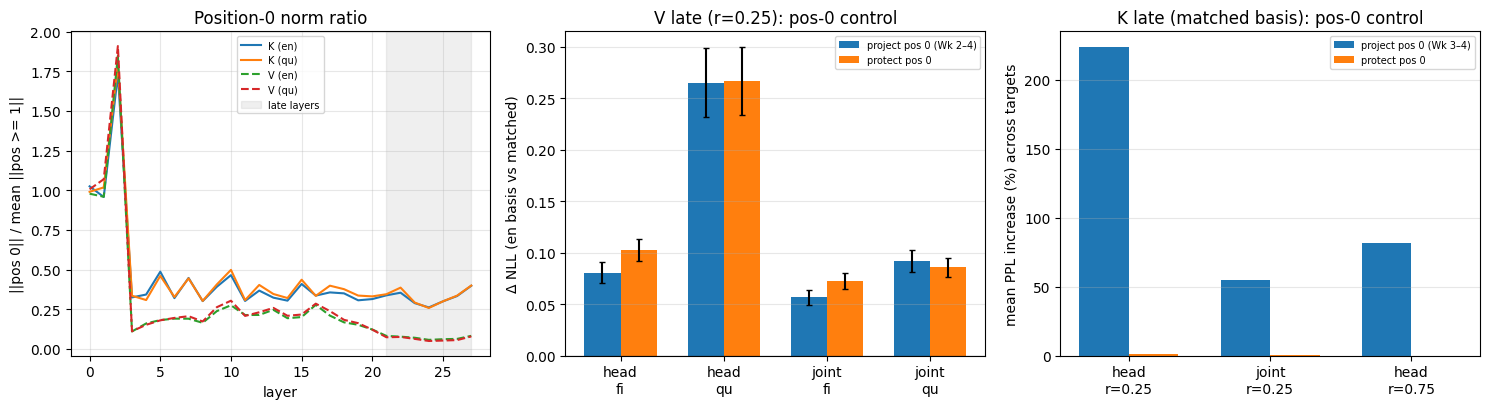

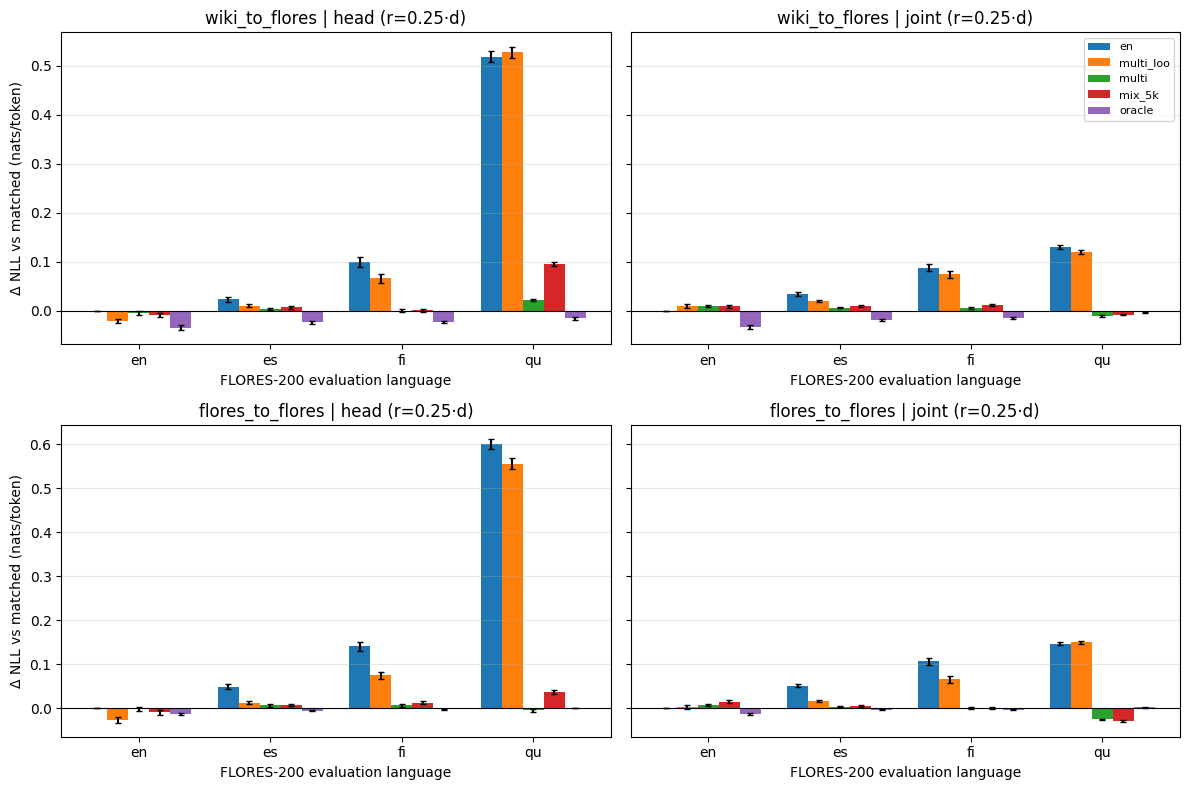

In [10]:
# Fig 1: Position-0 sink diagnostic & control (V and K)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# Panel 1: Pos-0 norm ratio by layer (K vs V)
ax = axes[0]
for kind, ls in (("K", "-"), ("V", "--")):
    for l in diag_langs:
        s = pos0_diag[(pos0_diag.kind == kind) & (pos0_diag.lang == l)]
        ax.plot(s.layer, s.norm_ratio, ls, label=f"{kind} ({l})")
ax.axvspan(LATE[0], LATE[-1], color="gray", alpha=0.12, label="late layers")
ax.set_xlabel("layer"); ax.set_ylabel("||pos 0|| / mean ||pos >= 1||")
ax.set_title("Position-0 norm ratio"); ax.legend(fontsize=7); ax.grid(alpha=0.3)

# Panel 2: V late (r=0.25) foreign-basis penalty on non-English targets: unprotected vs protected pos 0
ax = axes[1]
subV = resA[(resA.exp == "A1_V_late") & (resA.source == en_code)]
labels_v = [f"{sc}\n{tg}" for sc in SCOPES for tg in partA_targets if tg != en_code]
x = np.arange(len(labels_v)); w = 0.35
for idx, prot in enumerate((False, True)):
    vals, lo, hi = [], [], []
    for sc in SCOPES:
        for tg in partA_targets:
            if tg == en_code: continue
            q = subV[(subV.scope == sc) & (subV.target == tg) & (subV.protect_pos0 == prot)]
            y = q.delta_vs_matched.iloc[0]
            vals.append(y); lo.append(y - q.ci_low.iloc[0]); hi.append(q.ci_high.iloc[0] - y)
    ax.bar(x + (idx - 0.5) * w, vals, w, yerr=[lo, hi], capsize=2,
           label="protect pos 0" if prot else "project pos 0 (Wk 2–4)")
ax.axhline(0, color="k", lw=0.8); ax.set_xticks(x, labels_v)
ax.set_ylabel("Δ NLL (en basis vs matched)"); ax.set_title("V late (r=0.25): pos-0 control")
ax.legend(fontsize=7); ax.grid(axis="y", alpha=0.3)

# Panel 3: K late (matched basis) PPL increase (%) unprotected vs protected pos 0
ax = axes[2]
subK = resA[(resA.exp == "A2_K_late") & (resA.source == "matched")]
k_labels = [f"{sc}\nr={rf:g}" for sc, rf in k_settings]
x = np.arange(len(k_labels)); w = 0.35
for idx, prot in enumerate((False, True)):
    vals = [subK[(subK.scope == sc) & (subK.rank_frac == rf) & (subK.protect_pos0 == prot)].ppl_increase_pct.mean()
            for sc, rf in k_settings]
    ax.bar(x + (idx - 0.5) * w, vals, w, label="protect pos 0" if prot else "project pos 0 (Wk 3–4)")
ax.set_xticks(x, k_labels); ax.set_ylabel("mean PPL increase (%) across targets")
ax.set_title("K late (matched basis): pos-0 control"); ax.legend(fontsize=7); ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "fig1_pos0_control_kv.png"), dpi=150)
plt.show()

# Fig 2: FLORES-200 parallel control (delta NLL vs matched)
show_b = [s for s in [en_code, "multi_loo", "multi", "mix_5k", "oracle"] if s in SOURCES_B]
fig, axes = plt.subplots(len(REGIMES), len(SCOPES), figsize=(12, 4.0 * len(REGIMES)), sharey="row", squeeze=False)
w = 0.8 / len(show_b)
for i, regime in enumerate(REGIMES):
    for j, scope in enumerate(SCOPES):
        ax = axes[i][j]
        x = np.arange(len(LANGS))
        for k, s in enumerate(show_b):
            q = resB[(resB.regime == regime) & (resB.scope == scope) & (resB.source == s)].set_index("target").reindex(LANGS)
            y = np.nan_to_num(q.delta_nll.values)
            err = np.nan_to_num(np.vstack([q.delta_nll.values - q.ci_low.values, q.ci_high.values - q.delta_nll.values]))
            ax.bar(x + (k - (len(show_b) - 1) / 2) * w, y, w, yerr=err, capsize=2, label=s)
        ax.axhline(0, color="k", lw=0.8)
        ax.set_xticks(x, LANGS)
        ax.set_xlabel("FLORES-200 evaluation language")
        ax.set_title(f"{regime} | {scope} (r={R_V:g}·d)")
        ax.grid(axis="y", alpha=0.3)
    axes[i][0].set_ylabel("Δ NLL vs matched (nats/token)")
axes[0][-1].legend(fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "fig2_flores_parallel_control.png"), dpi=150)
plt.show()

## 7. Reading guide & next steps

1. **Part A — Position-0 control (`V`):**
   - If `en → qu` ΔNLL stays ~`0.26` (`head`) and ~`0.09` (`joint`) with `protect_pos0 = True`, then the cross-language calibration gap in late-layer values is **genuine** and not a position-0 sink artifact.
   - If protecting position 0 reduces baseline PPL cost too, adopt `protect_pos0 = True` as the clean default going forward (consistent with `SKIP_FIRST_TOKENS = 1` and real KV-cache sink preservation).

2. **Part A — Position-0 control (`K`) & reminder for dedicated `K` deep dive:**
   - Look at `A2_K_late` and `pos0_diagnostic.csv`:
     - If protecting position 0 drops `K` PPL increase sharply, the blow-up at `r = 0.75` was driven by truncating the attention sink at position 0.
     - If `K` *still* explodes even with `protect_pos0 = True`, the root cause is architectural/spectral (Qwen3's `k_norm` RMSNorm after `k_proj`, pre-RoPE vs post-RoPE projection, unequal head norms, or `Q·K^T` sensitivity vs unweighted `K` energy).
   - **Follow-up reminder (Week 5b / Deep dive on `K`):** inspect per-head `K` norms, test hooking *after* `k_norm` (and post-RoPE), and test `Q`-weighted / Fisher-weighted key bases to explain *why* `K` reacts so strongly compared to `V`.

3. **Part B — Parallel control (FLORES-200):**
   - Compare `wiki_to_flores` and `flores_to_flores`: if `en` and `multi_loo` still penalize Quechua while `joint` + `mix_5k` (`w = 0.10`, ~5k tokens) closes the gap on **exact parallel translations**, the topic/domain confounder in Wikipedia is ruled out.

**Artifacts to save / upload:** `partA_pos0_control.csv`, `partB_flores_ppl.csv`, `partB_flores_energy.csv`, `pos0_diagnostic.csv`, `baseline_ppl.json`, `fig1_pos0_control_kv.png`, `fig2_flores_parallel_control.png`.